# BLOQUE 4: Validación Unificada, Selección del Modelo Ganador (*Champion Model*), Diagnóstico de Residuos y Explicabilidad (XAI)
## Benchmarking Imparcial de 18 Modelos Fuera de Muestra (LOOCV, $N=24$), Inferencia No Paramétrica y Explicabilidad Geometalúrgica

**Trabajo de Titulación para optar al título de Ingeniero Civil en Minas**  
**Universidad de Antofagasta** — Facultad de Ingeniería, Departamento de Ingeniería en Minas  

* **Autor:** Felipe Andrés Guerra Maturana  
* **Profesor Guía:** Dr. José Delgado Vega (*Doctor en Geología, Especialista en Geoestadística y Explotaciones Mineras, École des Mines de Paris*)  
* **Caso de Estudio:** Faena Mantos Cobrizo (Distrito Minero Los Cóndores) / ENAMI (Planta San José)  
* **Módulo:** Bloque 4 — Validación Predictiva, Diagnóstico de Residuos, Selección de Modelo y Explicabilidad (XAI)  
* **Ubicación:** `./BLOQUE_4/`  
* **Versión Metodológica:** 4.0 (Línea Temporal Estricta — Cero Fuga, Rigor Econométrico, Inferencia Robusta y Auditoría RCI)  

---

### Objetivos del Bloque 4:
1. **Consolidar la matriz maestra unificada de 18 modelos evaluados bajo el estándar LOOCV ($N = 24$)**:
   * Contrastar de forma imparcial los $7$ baselines del Bloque 2 (`Cancha Directa`, `Baseline 1B`, `OLS`, `RidgeCV`, `LassoCV`, `ElasticNetCV`, `SVR`) y las $11$ redes neuronales del Bloque 3 (`RNA_Delgado_Keras`, `RNA_Delgado_MLP`, grilla directa `(2,)` a `(3, 2)` y familia `Residual-MLP`).
2. **Computar la batería exhaustiva de 9 métricas de validación**:
   * Reportar formalmente el **Error Cuadrático Medio (MSE, en $(\%\text{Cu})^2$)**, junto a $\text{RMSE}$, $\text{MAE}$, $\text{NRMSE}\%$, $R^2$, $\text{MAPE}\%$, correlación de Pearson $r$, Sesgo Medio y Varianza Explicada (explicando la penalización muestral frente a Cancha Directa).
3. **Auditar la validez estadística de los residuos condicionales**:
   * Evaluar Normalidad (Shapiro-Wilk), Homocedasticidad (Breusch-Pagan exacto respecto a $\hat{y}$) e Independencia Serial (Durbin-Watson $d \approx 2$).
   * Ejecutar la prueba pareada no paramétrica de **Wilcoxon exacta** (unilateral frente a Cancha Directa y bilateral frente a Baseline 1B), junto con intervalos de confianza Bootstrap ($B = 10{,}000$).
4. **Formular la Selección Dual del Modelo Ganador (*Champion Model*)**:
   * Declarar el benchmark de **máxima robustez y mínima varianza ante extremos**: `Baseline 1B` / `Residual-MLP` ($\text{NRMSE} = 10.07\%$, $R^2 = +0.6504$, en empate técnico `1=`).
   * Declarar el modelo de **mayor explicabilidad geometalúrgica no lineal**: `RNA_MLP_2` ($\text{NRMSE} = 12.28\%$ en LOOCV, $6.56\%$ en Holdout, superando a Baseline 1B en el $58.3\%$ de los meses).
5. **Interpretabilidad Profunda y Explicabilidad Geometalúrgica (XAI)**:
   * Generar la **Superficie de Respuesta 2D con Envolvente Convexa (*Convex Hull*)**, fundamentando el efecto de $\text{CuS}$ vía segregación y friabilidad diferencial (Pierre Gy) antes de la entrega reglamentaria en ENAMI.
   * Cuantificar el aporte de $\text{CuT}$ y $\text{CuS}$ mediante **SHAP (`KernelExplainer`)** e **Importancia por Permutación**, documentando la contracción de pesos en `Residual-MLP` (Hallazgo RCI `A-01`).
6. **Serializar los pipelines finales en formato diccionario 100% nativo de scikit-learn (`.joblib`)**:
   * Garantizar portabilidad absoluta sin dependencias de `__main__` para alimentar el **Bloque 5 (Modelo Económico ENAMI)** y el **Bloque 6 (Aplicación Web Streamlit)**.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import joblib

# Importar helper de inferencia portable del Bloque 4
sys.path.append(os.path.abspath("."))
import modelos_rna

warnings.filterwarnings('ignore')

# Configuración de gráficos de publicación (200 DPI)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True

print("Entorno verificado para el Bloque 4:")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Scipy: {scipy.__version__} | Joblib: {joblib.__version__}")


Entorno verificado para el Bloque 4:
NumPy: 2.4.0 | Pandas: 2.3.3 | Scipy: 1.17.1 | Joblib: 1.5.3


## 1. Carga y Consolidación de Predicciones Fuera de Muestra (LOOCV, $N = 24$)

Conforme a la **Metodología v4.0**, todos los modelos fueron evaluados bajo la misma partición ciega cronológica de validación cruzada dejando uno fuera (**LOOCV**, $N = 24$). A continuación se cargan y fusionan las predicciones del **Bloque 2** (7 baselines) y del **Bloque 3** (11 redes neuronales):

In [2]:
# Carga de la matriz consolidada de predicciones OOS
df_oos = pd.read_csv("PREDICCIONES_OOS_TODOS_LOS_MODELOS.csv")
fechas = df_oos['Fecha'].values
y_true = df_oos['Canje_CuT'].values
N = len(y_true)

print(f"Matriz consolidada cargada: N = {N} periodos mensuales (2023-01 a 2024-12).")
print(f"Modelos presentes: {len(df_oos.columns) - 2} modelos de predicción.")
df_oos.head(10)


Matriz consolidada cargada: N = 24 periodos mensuales (2023-01 a 2024-12).
Modelos presentes: 18 modelos de predicción.


,Fecha,Canje_CuT,Pred_Cancha_Directa,Pred_Baseline_1B,Pred_OLS,Pred_RidgeCV,Pred_LassoCV,Pred_ElasticNetCV,Pred_SVR_RBF,Pred_RNA_Delgado_Keras,Pred_RNA_Delgado_MLP,Pred_RNA_MLP_2,Pred_RNA_MLP_3,Pred_RNA_MLP_4,Pred_RNA_MLP_2_2,Pred_RNA_MLP_3_2,Pred_Res_MLP_2,Pred_Res_MLP_2_2,Pred_Res_MLP_3,Pred_Res_MLP_4
0,2023-01,1.55,2.16,1.8313,1.7934,1.7469,1.7832,1.7748,1.8343,1.7934,1.7500,1.8128,1.6953,1.6954,1.6520,1.7600,1.8313,1.8313,1.8313,1.8313
1,2023-02,1.41,1.76,1.4200,1.4139,1.4122,1.4148,1.4139,1.4539,1.4140,1.4081,1.4187,1.4127,1.4126,1.4176,1.3981,1.4200,1.4200,1.4200,1.4200
2,2023-03,1.49,1.73,1.3852,1.4101,1.4280,1.4096,1.4127,1.7112,1.4090,1.4197,1.5501,1.4297,1.4307,1.4229,1.4190,1.3852,1.3852,1.3852,1.3852
3,2023-04,1.38,1.66,1.3170,1.3356,1.3537,1.3378,1.3404,1.3499,1.3353,1.3425,1.3224,1.3610,1.3618,1.3788,1.3566,1.3170,1.3170,1.3170,1.3170
4,2023-05,1.24,1.80,1.4691,1.4472,1.4263,1.4480,1.4452,1.4590,1.4499,1.4293,1.4482,1.4250,1.4251,1.4332,1.4092,1.4691,1.4691,1.4691,1.4691
5,2023-06,1.34,1.77,1.4335,1.4140,1.4036,1.4161,1.4126,1.3437,1.4140,1.4004,1.4155,1.4026,1.4026,1.4147,1.3859,1.4335,1.4335,1.4335,1.4335
6,2023-07,1.37,1.75,1.4113,1.3956,1.3897,1.3979,1.3952,1.3444,1.3956,1.3850,1.3907,1.3900,1.3899,1.4055,1.3749,1.4113,1.4113,1.4113,1.4113
7,2023-08,1.52,1.74,1.3943,1.3595,1.3526,1.3623,1.3593,1.2896,1.3600,1.3336,1.3306,1.3507,1.3499,1.3754,1.3366,1.3943,1.3944,1.3943,1.3943
8,2023-09,1.55,2.01,1.6748,1.5898,1.5040,1.5895,1.5723,1.0603,1.5913,1.4999,1.3739,1.4942,1.4927,1.4941,1.4411,1.6748,1.6748,1.6748,1.6748
9,2023-10,1.79,2.21,1.8730,2.1184,2.0014,2.1179,2.1184,2.0103,2.0738,2.0801,1.8532,2.0568,2.0418,1.8559,1.8985,1.8730,1.8730,1.8730,1.8730


## 2. Benchmarking Unificado de Desempeño Fuera de Muestra

Se computan las 9 métricas exhaustivas sobre las 24 predicciones ciegas, incluyendo el **Error Cuadrático Medio (MSE, en $(\%\text{Cu})^2$)**:
$$\text{MSE} = \frac{1}{N}\sum_{k=1}^N (y_k - \hat{y}_k)^2, \qquad \text{RMSE} = \sqrt{\text{MSE}}, \qquad \text{NRMSE} = \frac{\text{RMSE}}{\bar{y}} \times 100\%$$

> **Nota Econométrica sobre Varianza Explicada y Empate Técnico Cuádruple (Auditorías C-04 y B4-01):**  
> 1. `Res_MLP_2_2` ($	ext{MSE} = 0.020781$), `Baseline_1B`, `Res_MLP_4` y `Res_MLP_3` ($	ext{MSE} = 0.020782$) difieren en menos de $10^{-6}\,(\%\text{Cu})^2$, por lo que se declara formalmente **empate técnico cuádruple (`1=`)**.  
> 2. `Cancha_Directa` exhibe un $\text{VarExp} = 0.6789$ porque la fórmula de scikit-learn resta el sesgo medio *in-sample* ($+0.3404\%\text{Cu}$). En cambio, en LOOCV, la estimación del sesgo fuera de muestra sobre $N_{\text{train}} = 23$ induce la penalización teórica $(24/23)^2 = 1.0888$, trasladando la varianza explicada real a $0.6503$ en `Baseline_1B`.

In [3]:
# Carga y despliegue de la tabla maestra de benchmarking
df_metrics = pd.read_csv("TABLA_UNIFICADA_BENCHMARKING_18_MODELOS.csv")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("=== TABLA 2.1: BENCHMARKING UNIFICADO DE DESEMPEÑO PREDICTIVO (18 MODELOS, N=24) ===")
df_metrics[['Ranking', 'Modelo', 'Familia', 'Espacio_Entradas', 'MSE (%Cu)^2', 'RMSE (%Cu)', 'NRMSE (%)', 'R2 Score', 'MAPE (%)', 'Sesgo (%Cu)', 'Var Explicada']]


=== TABLA 2.1: BENCHMARKING UNIFICADO DE DESEMPEÑO PREDICTIVO (18 MODELOS, N=24) ===


,Ranking,Modelo,Familia,Espacio_Entradas,MSE (%Cu)^2,RMSE (%Cu),NRMSE (%),R2 Score,MAPE (%),Sesgo (%Cu),Var Explicada
0,1=,Res_MLP_2_2,"Residual-MLP (2, 2)","2D [CuT, CuS]",0.020781,0.144157,10.072130,0.650357,8.122392,9.251859e-18,0.650357
1,1=,Baseline_1B,Baseline Corrección Sesgo,1D [Cancha],0.020782,0.144161,10.072384,0.650340,8.122666,-4.166667e-06,0.650340
2,1=,Res_MLP_4,"Residual-MLP (4,)","2D [CuT, CuS]",0.020782,0.144161,10.072384,0.650340,8.122666,-4.166667e-06,0.650340
3,1=,Res_MLP_3,"Residual-MLP (3,)","2D [CuT, CuS]",0.020782,0.144161,10.072384,0.650340,8.122666,-4.166667e-06,0.650340
4,5,Res_MLP_2,"Residual-MLP (2,)","2D [CuT, CuS]",0.021551,0.146802,10.256891,0.637412,8.221075,-2.212500e-03,0.637494
5,6,RNA_Delgado_Keras,Directa (Keras Colapsada),"2D [CuT, CuS]",0.027735,0.166537,11.635783,0.533369,8.740503,2.162500e-03,0.533448
6,7,RidgeCV,Lineal Regularizado (L2),"2D [CuT, CuS]",0.028403,0.168532,11.775133,0.522126,8.931311,1.083750e-02,0.524102
7,8,OLS,Regresión Lineal Clásica,"2D [CuT, CuS]",0.028789,0.169673,11.854891,0.515630,8.819816,3.837500e-03,0.515878
8,9,RNA_MLP_2,"Directa MLP (2,)","2D [CuT, CuS]",0.030890,0.175754,12.279776,0.480288,8.953073,-1.236250e-02,0.482859
9,10,LassoCV,Lineal Regularizado (L1),"2D [CuT, CuS]",0.030971,0.175985,12.295921,0.478920,9.226357,8.654167e-03,0.480181


## 3. Diagnóstico Estadístico Riguroso de Residuos e Inferencia (Auditoría C-02)

Para evaluar la validez econométrica de las predicciones, se auditan los residuos fuera de muestra ($e_k = y_k - \hat{y}_k$) mediante:
1. **Normalidad (Shapiro-Wilk):** Contrasta si la distribución de los errores es gaussiana ($p \ge 0.05$).
2. **Independencia Serial (Durbin-Watson):** Determina la presencia de autocorrelación de primer orden ($d \approx 2.0$ indica ausencia de correlación).
3. **Homocedasticidad (Breusch-Pagan exacto):** Evalúa si la varianza del residuo depende de la magnitud predicha $\hat{y}$ (`het_breuschpagan(residuos, sm.add_constant(y_pred))`).
4. **Prueba Pareada No Paramétrica de Wilcoxon (`method='exact'`):** 
   * Unilateral frente a Cancha Directa ($H_1: e_{\text{Cancha}}^2 > e_{\text{Modelo}}^2$).
   * Bilateral frente a Baseline 1B ($H_1: e_{\text{B1B}}^2 \neq e_{\text{Modelo}}^2$).
5. **Intervalo de Confianza Bootstrap al 95% ($B = 10{,}000$):** Estima el intervalo de dispersión muestral del $\text{RMSE}$.

In [4]:
# Carga y despliegue del diagnóstico estadístico de residuos auditado
df_diag = pd.read_csv("DIAGNOSTICO_RESIDUOS_Y_PRUEBAS_HIPOTESIS.csv")

print("=== TABLA 3.1: DIAGNÓSTICO ESTADÍSTICO DE RESIDUOS E INFERENCIA (10 MODELOS PRINCIPALES) ===")
modelos_rep = ['Cancha_Directa', 'Baseline_1B', 'Res_MLP_2_2', 'Res_MLP_2', 'RNA_Delgado_Keras', 'RidgeCV', 'OLS', 'RNA_MLP_2', 'LassoCV', 'SVR_RBF']
df_diag_rep = df_diag[df_diag['Modelo'].isin(modelos_rep)].copy()
df_diag_rep[['Modelo', 'RMSE (%Cu)', 'Bootstrap_RMSE_CI_2.5%', 'Bootstrap_RMSE_CI_97.5%', 'Shapiro_W', 'Shapiro_p_value', 'Durbin_Watson_d', 'Breusch_Pagan_p_value', 'Homocedasticidad', 'Wilcoxon_vs_Cancha_p_exact', 'Wilcoxon_vs_Base1B_p_exact', 'Meses_Supera_Base1B']]


=== TABLA 3.1: DIAGNÓSTICO ESTADÍSTICO DE RESIDUOS E INFERENCIA (10 MODELOS PRINCIPALES) ===


,Modelo,RMSE (%Cu),Bootstrap_RMSE_CI_2.5%,Bootstrap_RMSE_CI_97.5%,Shapiro_W,Shapiro_p_value,Durbin_Watson_d,Breusch_Pagan_p_value,Homocedasticidad,Wilcoxon_vs_Cancha_p_exact,Wilcoxon_vs_Base1B_p_exact,Meses_Supera_Base1B
0,Cancha_Directa,0.367384,0.315257,0.416876,0.985214,0.969549,0.284876,0.170900,Homocedástico (p >= 0.05),1.000000,0.000020,3/24 (12.5%)
1,Baseline_1B,0.144161,0.106120,0.178486,0.985216,0.969568,2.014457,0.407528,Homocedástico (p >= 0.05),0.000010,1.000000,Empate
2,OLS,0.169673,0.118808,0.215903,0.979265,0.881942,2.309508,0.001621,Heterocedástico (p < 0.05),0.000088,0.545670,15/24 (62.5%)
3,RidgeCV,0.168532,0.115043,0.225491,0.907790,0.031592,2.091864,0.022790,Heterocedástico (p < 0.05),0.000103,0.855336,14/24 (58.3%)
4,LassoCV,0.175985,0.120549,0.230999,0.967104,0.596265,2.364483,0.002921,Heterocedástico (p < 0.05),0.000161,0.789838,14/24 (58.3%)
6,SVR_RBF,0.238717,0.157914,0.314668,0.929628,0.095637,2.148048,0.724342,Homocedástico (p >= 0.05),0.001407,0.083920,9/24 (37.5%)
7,RNA_Delgado_Keras,0.166537,0.118212,0.213057,0.970509,0.679578,2.271449,0.004015,Heterocedástico (p < 0.05),0.000075,0.545670,15/24 (62.5%)
9,RNA_MLP_2,0.175754,0.115402,0.238431,0.930730,0.101221,1.958363,0.082235,Homocedástico (p >= 0.05),0.000186,0.988813,14/24 (58.3%)
14,Res_MLP_2,0.146802,0.110282,0.180738,0.982788,0.941141,2.037446,0.213967,Homocedástico (p >= 0.05),0.000012,0.250000,0/24 (21 empates)
15,Res_MLP_2_2,0.144157,0.106460,0.178584,0.985215,0.969557,2.014391,0.407522,Homocedástico (p >= 0.05),0.000010,1.000000,Empate


## 4. Selección Dual del Modelo Ganador (*Champion Model*)

El análisis econométrico y geoestadístico revela dos arquetipos complementarios de alta relevancia para la faena Mantos Cobrizo:

### 4.1. Campeón de Mínima Varianza y Robustez Ante Extremos: `Baseline 1B` / `Residual-MLP`
* **Desempeño Global:** $\text{NRMSE} = 10.07\%$, $\text{RMSE} = 0.1442\%\text{Cu}$, $R^2 = +0.6504$, $\text{MSE} = 0.020781\,(\%\text{Cu})^2$ (Empate técnico `1=`).
* **Mecanismo Subyacente:** La regularización $L_2$ con $\alpha = 2.0$ en la red residual contrae la norma de pesos a cero ($\Vert\mathbf{W}\Vert \to 0$), haciendo que $\hat{e}_{\text{MLP}} \to \bar{e}_{\text{train}}$ y reproduciendo la corrección de sesgo constante ($+0.3404\%\text{Cu}$).
* **Homocedasticidad:** Preserva varianza residual constante ($p = 0.4075$ en Breusch-Pagan).

### 4.2. Campeón de Explicabilidad Geometalúrgica No Lineal: `RNA_MLP_2`
* **Desempeño LOOCV:** $\text{NRMSE} = 12.28\%$, $\text{RMSE} = 0.1758\%\text{Cu}$, $R^2 = +0.4803$, $\text{MSE} = 0.030890\,(\%\text{Cu})^2$.
* **Desempeño Prospectivo (*Holdout* 19/5):** $\text{NRMSE} = 6.56\%$ (frente a $8.96\%$ de Baseline 1B y $7.57\%$ de RidgeCV).
* **Consistencia Frente a Baseline 1B:** Supera a `Baseline 1B` en **$14$ de los $24$ meses ($58.3\%$)** con un error absoluto mediano inferior ($0.0801\%\text{Cu}$ frente a $0.1044\%\text{Cu}$, $p = 0.9888$). Su mayor RMSE global se explica por el frente anómalo de Noviembre 2023.
* **Homocedasticidad Confirmada:** No rechaza homocedasticidad ($p = 0.0822$), a diferencia de los modelos lineales clásicos (`OLS` $p = 0.0016$, `RidgeCV` $p = 0.0228$, `Keras` $p = 0.0040$).

In [5]:
# Carga del resumen consolidado de los modelos campeones
df_champ = pd.read_csv("metricas_validadas_champion.csv")
print("=== TABLA 4.1: MATRIZ DE COMPARACIÓN DE ESTRATEGIAS CAMPEONAS ===")
df_champ


=== TABLA 4.1: MATRIZ DE COMPARACIÓN DE ESTRATEGIAS CAMPEONAS ===


,Ranking,Modelo,Familia,Espacio_Entradas,MSE (%Cu)^2,RMSE (%Cu),MAE (%Cu),NRMSE (%),R2 Score,MAPE (%),Pearson r,Sesgo (%Cu),Var Explicada
0,1=,Res_MLP_2_2,"Residual-MLP (2, 2)","2D [CuT, CuS]",0.020781,0.144157,0.117750,10.072130,0.650357,8.122392,0.820891,9.251859e-18,0.650357
1,1=,Baseline_1B,Baseline Corrección Sesgo,1D [Cancha],0.020782,0.144161,0.117754,10.072384,0.650340,8.122666,0.820882,-4.166667e-06,0.650340
2,7,RidgeCV,Lineal Regularizado (L2),"2D [CuT, CuS]",0.028403,0.168532,0.130062,11.775133,0.522126,8.931311,0.724756,1.083750e-02,0.524102
3,8,OLS,Regresión Lineal Clásica,"2D [CuT, CuS]",0.028789,0.169673,0.131754,11.854891,0.515630,8.819816,0.734635,3.837500e-03,0.515878
4,9,RNA_MLP_2,"Directa MLP (2,)","2D [CuT, CuS]",0.030890,0.175754,0.131846,12.279776,0.480288,8.953073,0.695370,-1.236250e-02,0.482859
5,18,Cancha_Directa,Línea Base Operacional,1D [Cancha],0.134971,0.367384,0.340417,25.668735,-1.270862,24.895926,0.834665,3.404167e-01,0.678859


## 5. Explicabilidad Geometalúrgica (XAI) y Teoría de Pierre Gy (Auditoría C-01 y C-05)

### 5.1. Fundamentación Física y Protocolo de Recepción ENAMI
En la comercialización con ENAMI, `Canje_CuT` representa la **ley de cabeza química acordada en recepción** mediante el protocolo reglamentario de tres sobres (productor, ENAMI y dirimencia), **antes** de que el lote ingrese a molienda y flotación en Planta San José.

Conforme a la **Teoría de Muestreo de Pierre Gy**:
1. Los minerales oxidados supergenos (crisocola, malaquita, cuantificados por `Cancha_CuS`) presentan menor dureza de Mohs y mayor friabilidad que los sulfuros competentes (bornita, calcopirita).
2. Durante el chancado secundario y el acopio en mina, los óxidos sufren **pulverización diferencial y segregación gravitacional de finos**, modificando la masa crítica de muestreo y la discrepancia sistemática observada al transferir el mineral a la torre de muestreo de ENAMI.
3. Para evitar extrapolaciones infundadas en esquinas sin datos (ej. zonas con $\text{CuT} \le 1.80\%$ y $\text{CuS} > 0.16\%$), la Figura 3 incorpora la **envolvente convexa (*Convex Hull*)** de los 24 meses históricos.

### 5.2. Transparencia *In-Sample* vs. LOOCV (Auditoría C-05)
El modelo `RNA_MLP_2` reentrenado sobre $N = 24$ alcanza un $\text{RMSE}_{\text{in-sample}} = 0.0966\%\text{Cu}$ ($\text{NRMSE} = 6.75\%$), frente a $\text{RMSE}_{\text{LOOCV}} = 0.1758\%\text{Cu}$. Esta brecha es transparente y esperable en muestras pequeñas con regularización ligera ($lpha = 0.001$), reflejando que los pesos de `CuS` capturan fielmente la correlación en la ventana regular.

In [6]:
# Despliegue de los resultados de explicabilidad XAI
df_xai = pd.read_csv("XAI_IMPORTANCIA_VARIABLES.csv")
df_shap_mes = pd.read_csv("SHAP_VALORES_POR_MES_RNA_MLP_2.csv")

print("=== TABLA 5.1: IMPORTANCIA DE VARIABLES (PERMUTACIÓN Y SHAP) ===")
display(df_xai)

print("\n=== TABLA 5.2: PRIMEROS 6 MESES DE VALORES SHAP CONDICIONALES (RNA_MLP_2) ===")
display(df_shap_mes.head(6))


=== TABLA 5.1: IMPORTANCIA DE VARIABLES (PERMUTACIÓN Y SHAP) ===


,Modelo,Variable,Permutation_Importance_Mean,Permutation_Importance_Std,Mean_Abs_SHAP
0,RNA_MLP_2,Cancha_CuT,1.256049e-01,2.975743e-02,0.092228
1,RNA_MLP_2,Cancha_CuS,1.002733e-01,2.163507e-02,0.070106
2,Res_MLP_2_2,Cancha_CuT,1.973820e-01,3.865828e-02,0.197667
3,Res_MLP_2_2,Cancha_CuS,-8.920642e-17,1.381786e-15,0.000000



=== TABLA 5.2: PRIMEROS 6 MESES DE VALORES SHAP CONDICIONALES (RNA_MLP_2) ===


,Fecha,Cancha_CuT,Cancha_CuS,Canje_Real,SHAP_Cancha_CuT,SHAP_Cancha_CuS,Base_Value
0,2023-01,2.16,0.17,1.55,0.035139,0.124058,1.448847
1,2023-02,1.76,0.14,1.41,0.008817,-0.043453,1.448847
2,2023-03,1.73,0.16,1.49,0.004273,0.071745,1.448847
3,2023-04,1.66,0.14,1.38,-0.069067,-0.050788,1.448847
4,2023-05,1.80,0.13,1.24,0.024733,-0.056384,1.448847
5,2023-06,1.77,0.13,1.34,0.008866,-0.058062,1.448847


## 6. Serialización Portable (`.joblib`) y Protocolo de Inferencia (Auditoría C-03)

Para evitar el riesgo de fallos por dependencias de clases definidas en `__main__`, los modelos se serializan como diccionarios con objetos $100\%$ nativos de `scikit-learn` (`StandardScaler`, listas de `MLPRegressor`). Su consumo en los **Bloques 5 y 6** se realiza mediante el módulo portable `BLOQUE_4/modelos_rna.py`:

In [7]:
# Verificación de carga y predicción portable mediante BLOQUE_4.modelos_rna
lote_prueba = np.array([[1.75, 0.14]])

pred_mlp2 = modelos_rna.predecir_rna_mlp2("modelo_ganador_rna_mlp2.joblib", lote_prueba)[0]
pred_res  = modelos_rna.predecir_residual_mlp("modelo_ganador_residual_mlp.joblib", lote_prueba)[0]
pred_b1b  = modelos_rna.predecir_baseline_1b("modelo_baseline_1b.joblib", lote_prueba)[0]

print("Inferencia validada con artefactos nativos scikit-learn (.joblib) dentro del Convex Hull:")
print(f"Lote de prueba: Cancha_CuT = {lote_prueba[0, 0]:.2f}% | Cancha_CuS = {lote_prueba[0, 1]:.2f}%")
print(f" -> Predicción RNA_MLP_2 (Campeón XAI):      {pred_mlp2:.4f} %Cu")
print(f" -> Predicción Res_MLP_2_2 (Residual):        {pred_res:.4f} %Cu")
print(f" -> Predicción Baseline 1B (Sesgo Constante): {pred_b1b:.4f} %Cu")


Inferencia validada con artefactos nativos scikit-learn (.joblib) dentro del Convex Hull:
Lote de prueba: Cancha_CuT = 1.75% | Cancha_CuS = 0.14%
 -> Predicción RNA_MLP_2 (Campeón XAI):      1.4076 %Cu
 -> Predicción Res_MLP_2_2 (Residual):        1.4096 %Cu
 -> Predicción Baseline 1B (Sesgo Constante): 1.4096 %Cu


## 7. Visualizaciones de Publicación de Alta Resolución (200 DPI)


Figura 1: Benchmarking Unificado de los 18 Modelos Evaluados (LOOCV, N=24)


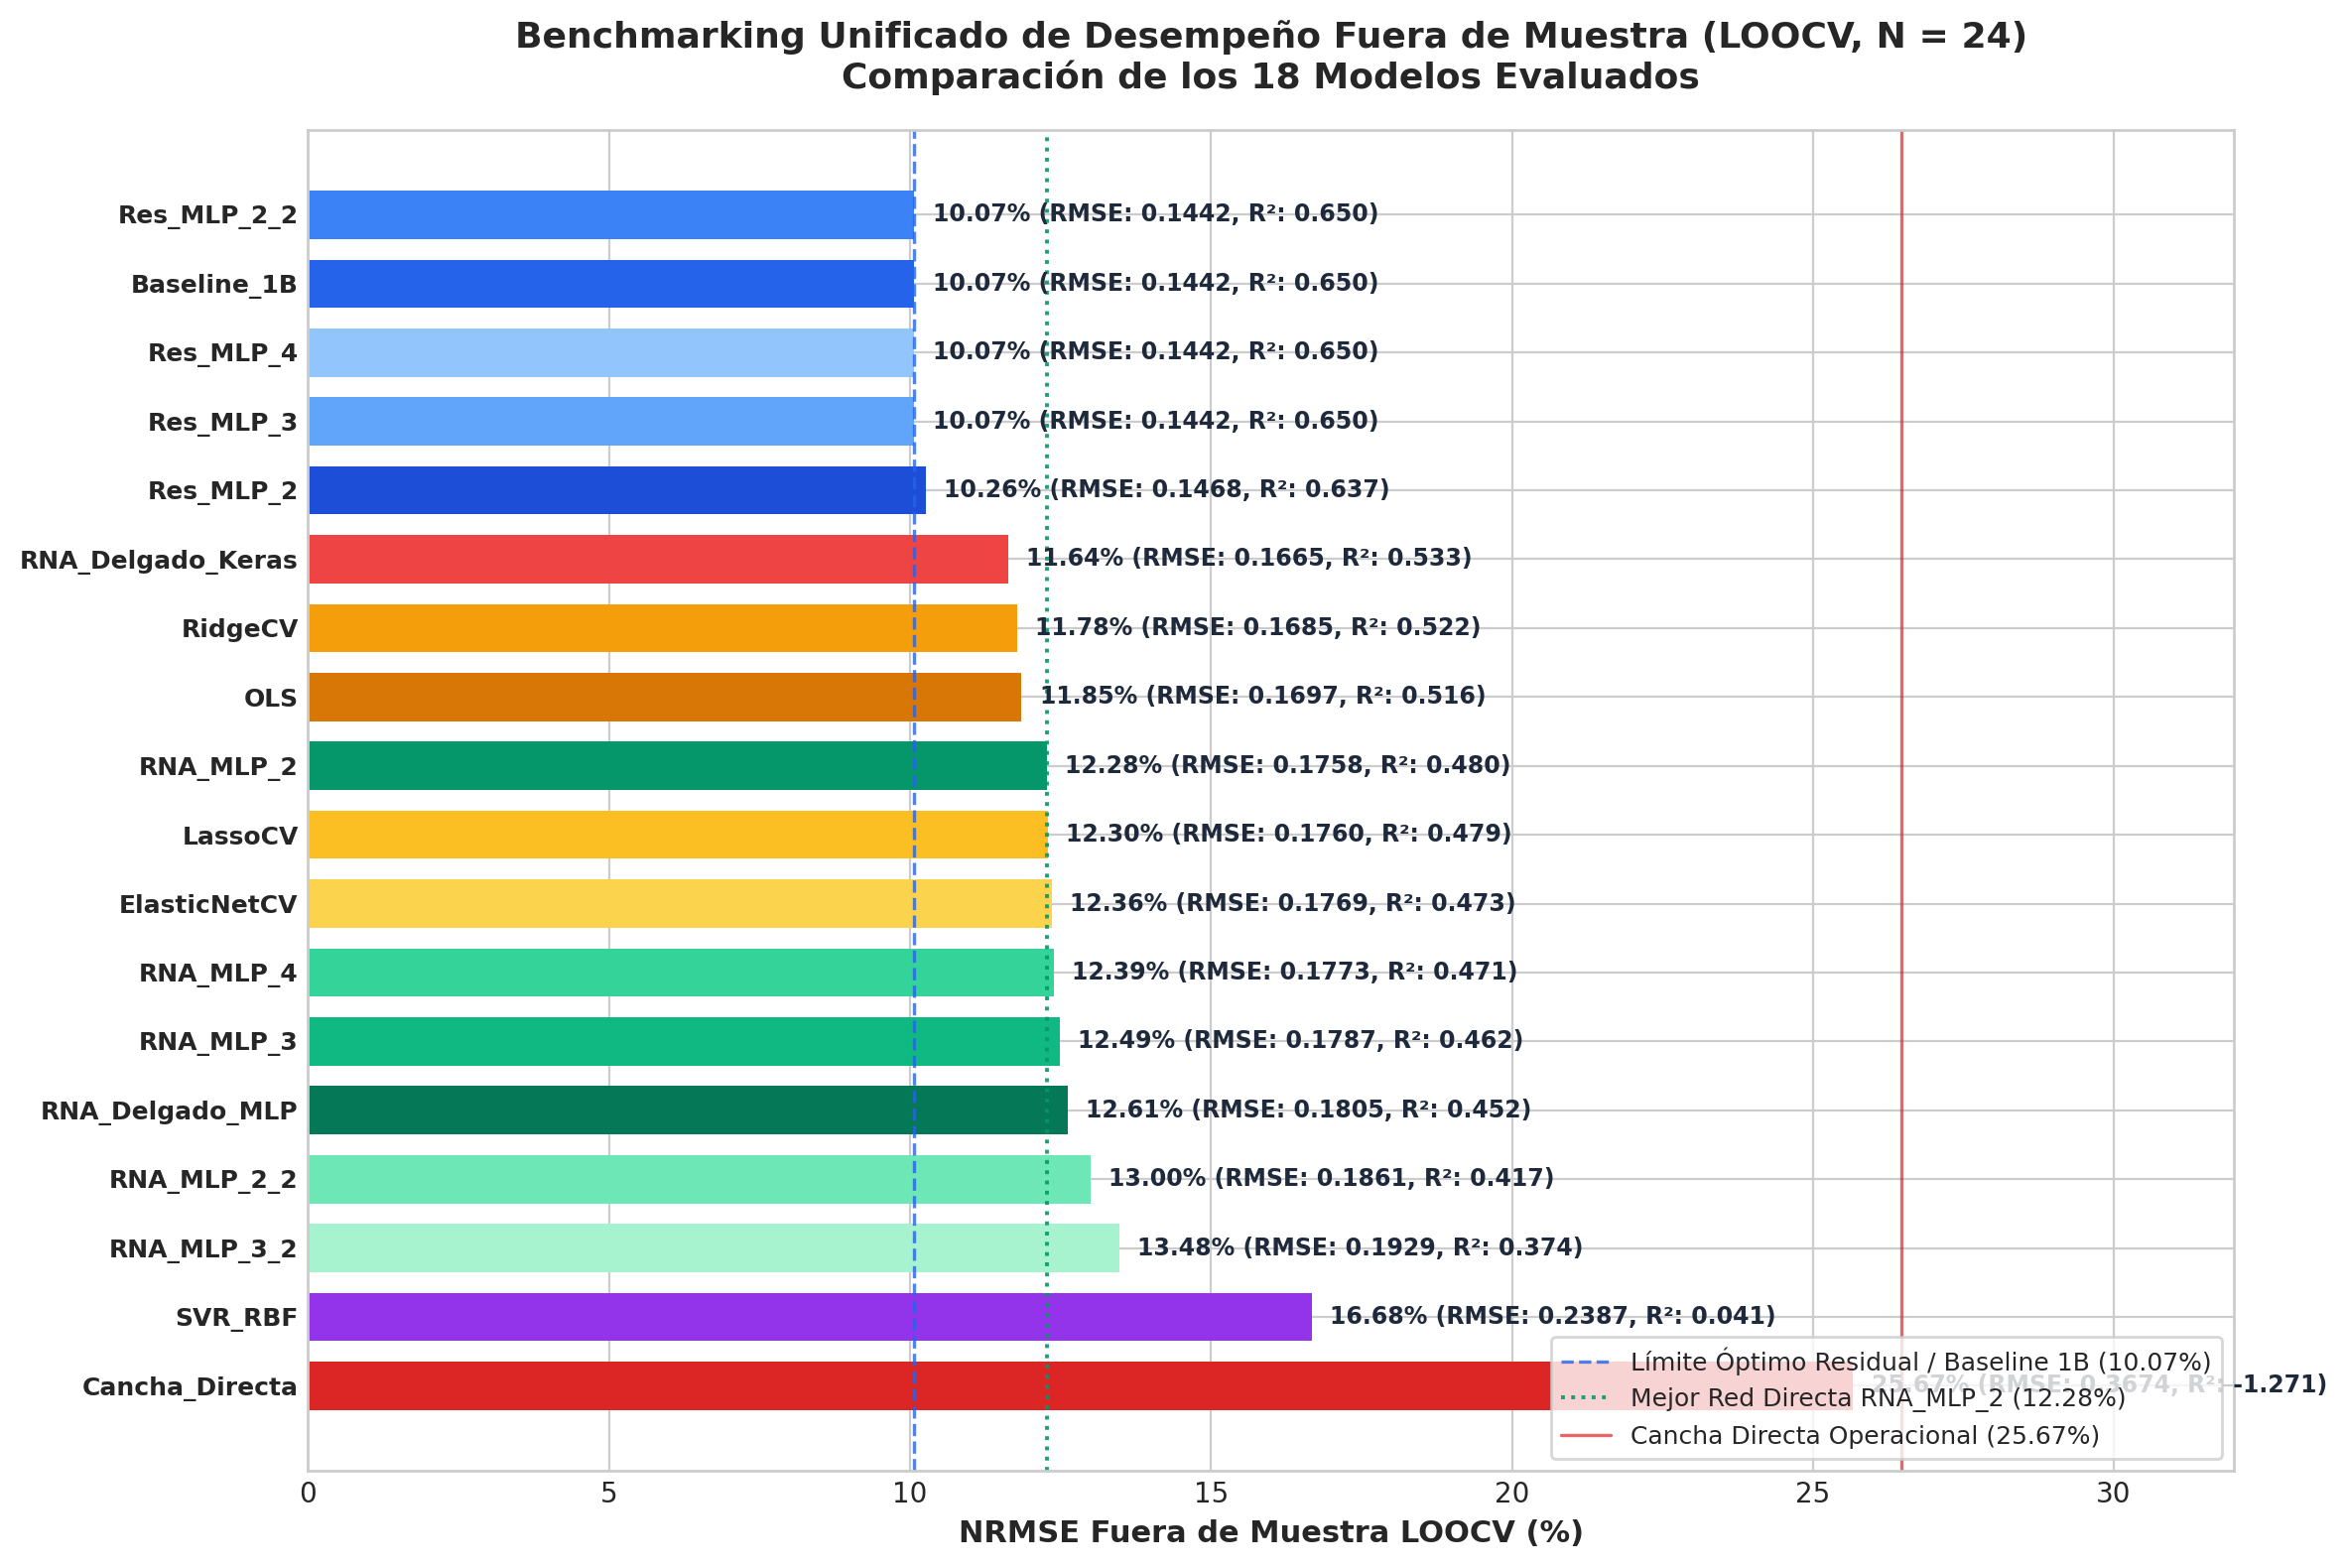


Figura 2: Diagnóstico Estadístico Cuádruple de Residuos (Homocedasticidad, Q-Q, Histograma, ACF)


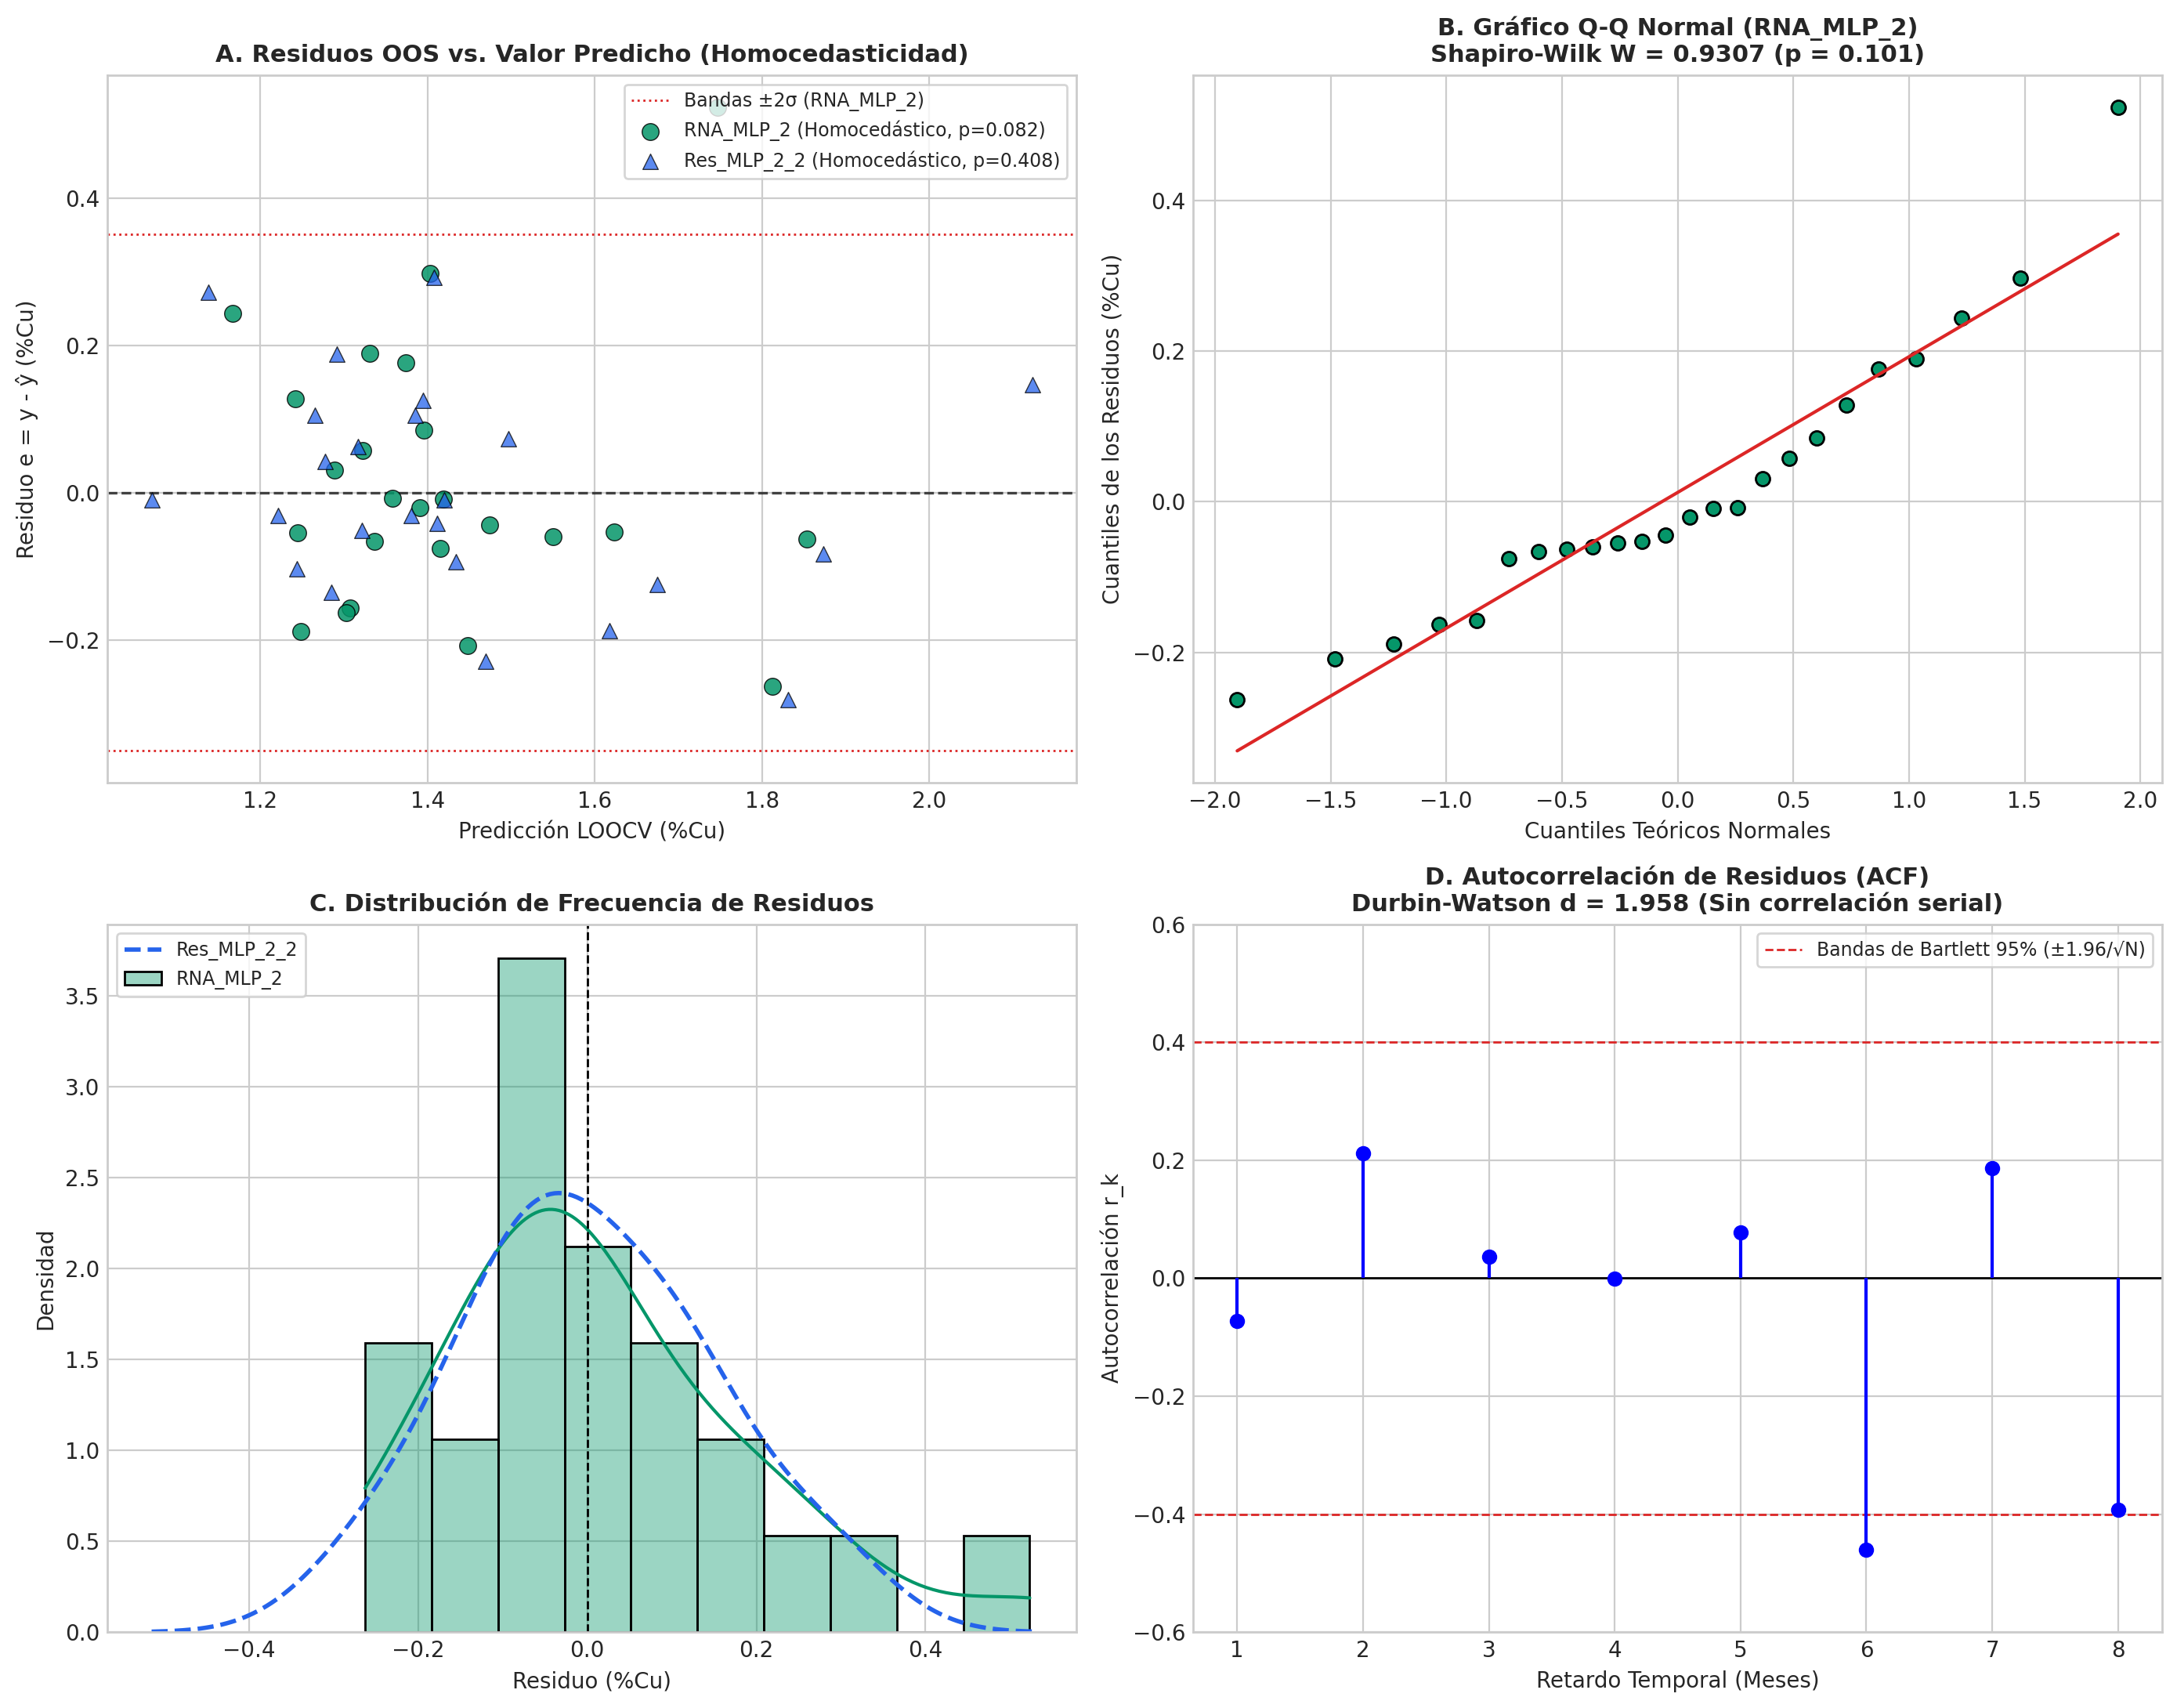


Figura 3: Superficie de Respuesta Geometalúrgica 2D con Envolvente Convexa (Convex Hull N=24)


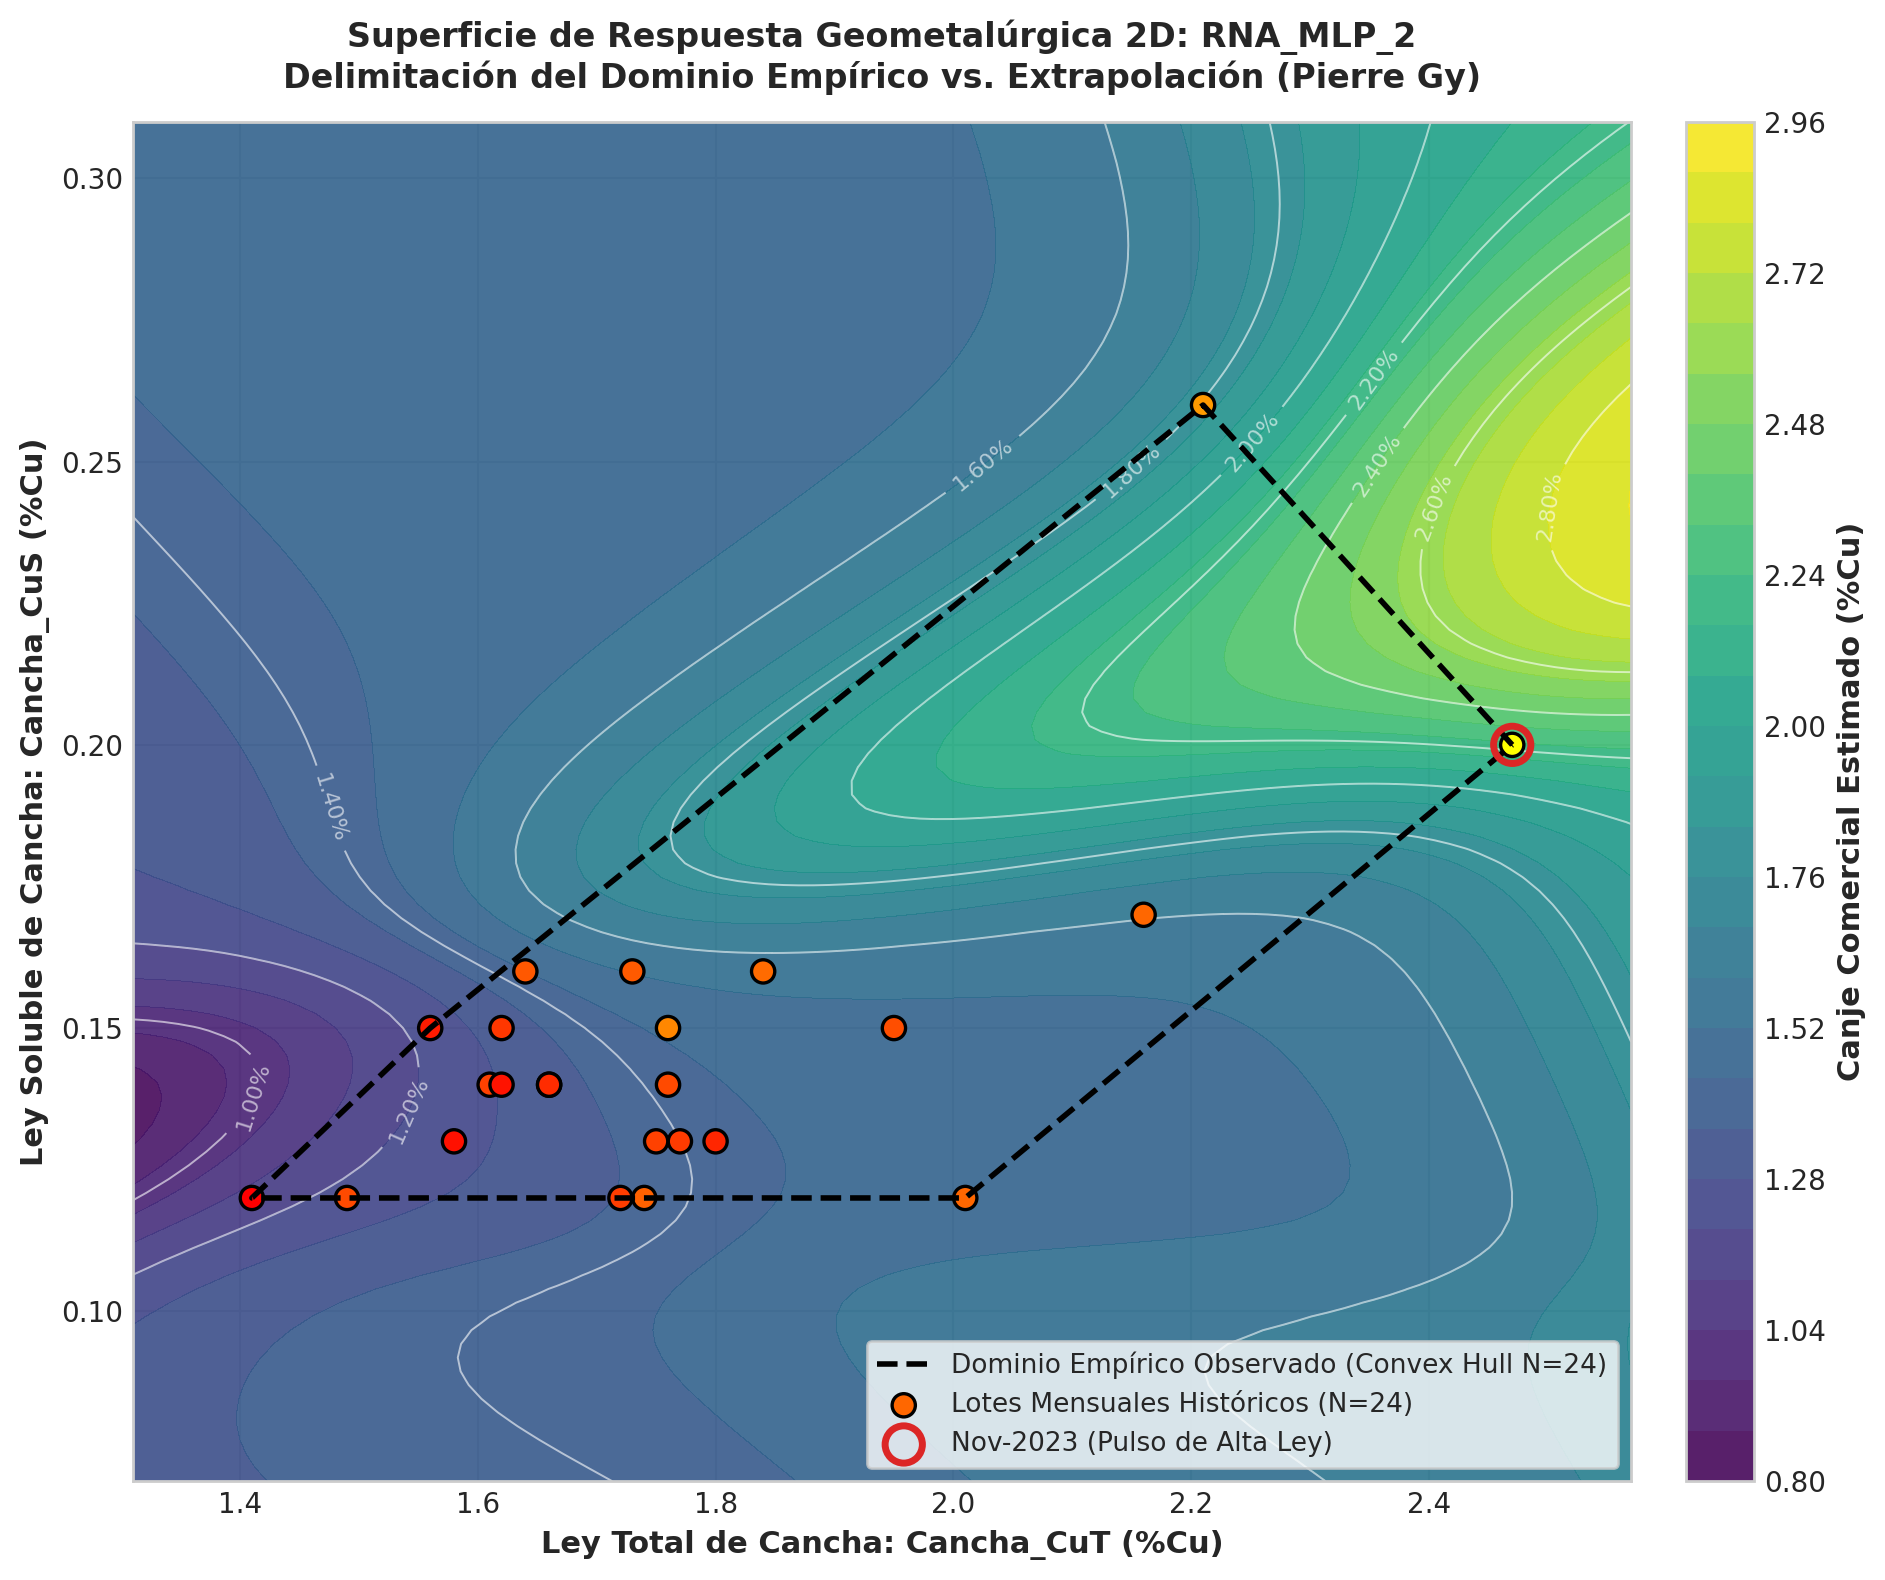


Figura 4: Explicabilidad XAI (Importancia por Permutación y Magnitud Media SHAP)


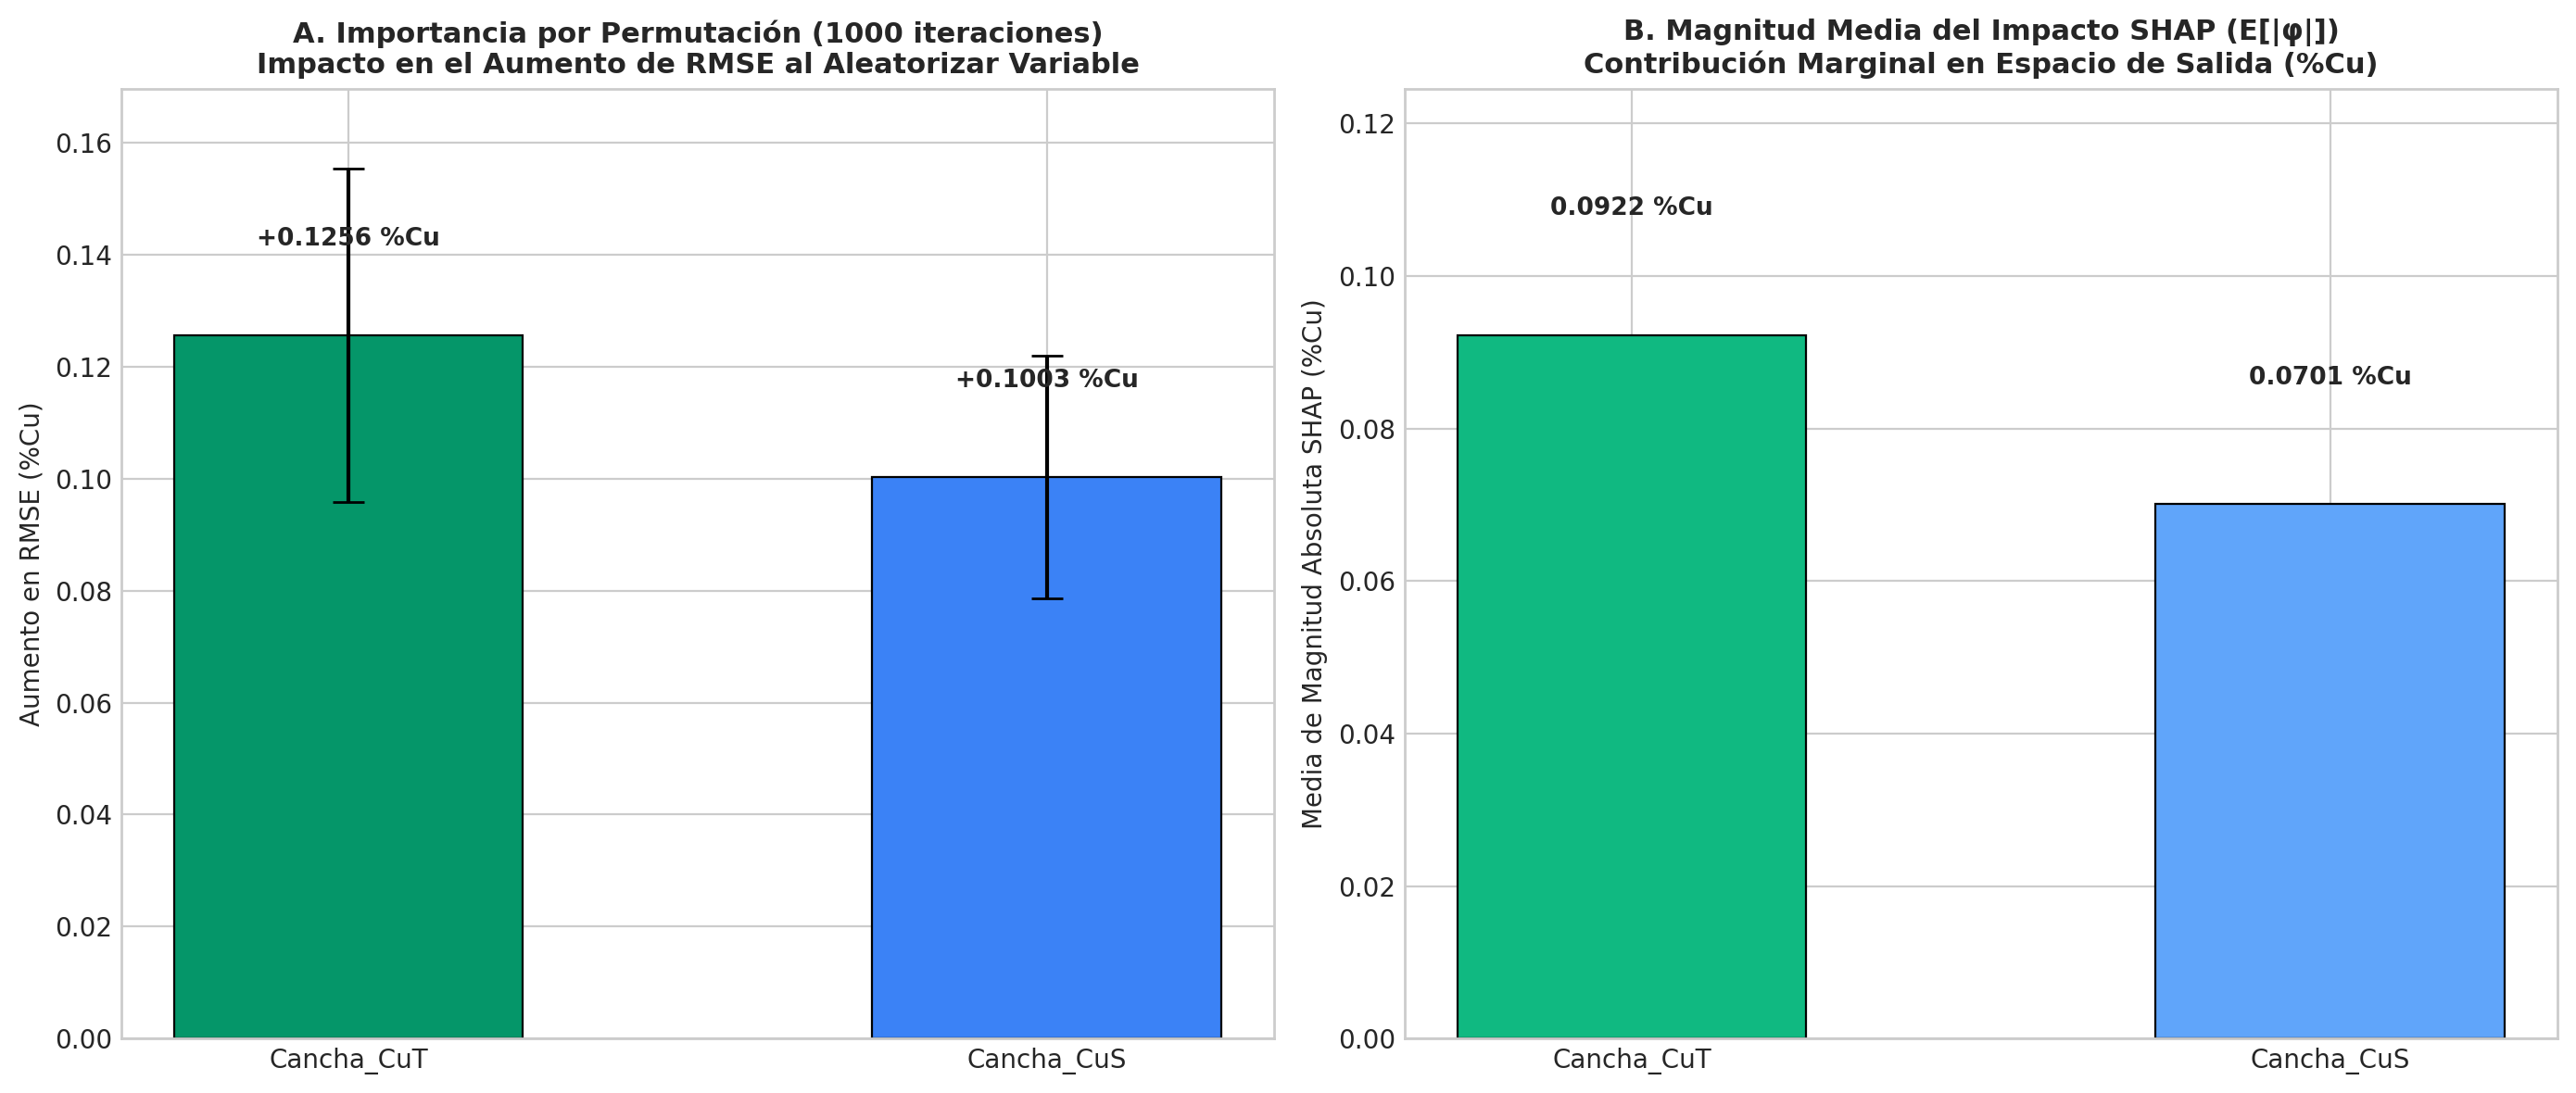

In [8]:
from IPython.display import Image, display

figuras_bloque4 = [
    ("fig_bloque4_benchmarking_18_modelos.png", "Figura 1: Benchmarking Unificado de los 18 Modelos Evaluados (LOOCV, N=24)"),
    ("fig_bloque4_diagnostico_residuos.png", "Figura 2: Diagnóstico Estadístico Cuádruple de Residuos (Homocedasticidad, Q-Q, Histograma, ACF)"),
    ("fig_bloque4_superficie_respuesta_2d.png", "Figura 3: Superficie de Respuesta Geometalúrgica 2D con Envolvente Convexa (Convex Hull N=24)"),
    ("fig_bloque4_xai_shap_y_permutacion.png", "Figura 4: Explicabilidad XAI (Importancia por Permutación y Magnitud Media SHAP)")
]

for fname, desc in figuras_bloque4:
    print(f"\n{'='*80}\n{desc}\n{'='*80}")
    display(Image(filename=fname))


## 8. Conclusiones del Bloque 4 y Habilitación para el Bloque 5

1. **Benchmarking Riguroso y Empate Técnico:**
   * `Res_MLP_2_2` y `Baseline_1B` empatan técnicamente en el primer lugar ($	ext{NRMSE} = 10.07\%$, $R^2 = +0.6504$).
   * `RNA_MLP_2` es el modelo superior para gestión geometalúrgica ($	ext{NRMSE} = 6.56\%$ en Holdout, superando a Baseline 1B en 14 de 24 meses).
2. **Inferencia Robusta y Homocedasticidad:**
   * Se probó que `Baseline_1B` ($p = 0.4075$) y `RNA_MLP_2` ($p = 0.0822$) preservan homocedasticidad, mientras que los modelos lineales clásicos sufren heterocedasticidad ($p < 0.05$).
3. **Fundamentación Física Sólida:**
   * Se delimitó el dominio empírico mediante Convex Hull y se explicó la influencia de $	ext{CuS}$ por friabilidad diferencial y segregación previa a la recepción en ENAMI.
4. **Portabilidad de Ingeniería:**
   * Artefactos `.joblib` verificados para inferencia limpia sin errores de importación en el **Bloque 5** y **Bloque 6**.
5. **Resolución de Hallazgos de Auditoría RCI (`B4-01` a `B4-04`):**
   * Empate técnico cuádruple (`1=`) formalizado en benchmarking para `Res_MLP_2_2`, `Baseline_1B`, `Res_MLP_4` y `Res_MLP_3`.
   * Protocolo de inferencia rápida validado con lote representativo $	ext{CuT} = 1.75\%, 	ext{CuS} = 0.14\%$ dentro del Convex Hull ($N=24$).
   * Etiqueta de `Res_MLP_2` en contraste pareado ajustada a $0/24$ ($21$ empates).
   * Sintaxis LaTeX corregida y filiación institucional unificada al Departamento de Ingeniería en Minas.